# TRABALHO PRÁTICO 1 - Inteligência Artificial
**DOCENTE:** Professora Érica Carvalho
**TEMA:** Segmentação de Clientes de Cartão de Crédito com Aprendizagem não Supervisionada.

---

## 1. Definição do Problema e Contextualização
As operadoras de cartões de crédito recolhem continuamente dados transacionais dos utilizadores. Compreender perfis de consumo e de pagamento permite desenhar limites de crédito ajustados ao risco, propor campanhas comerciais direcionadas e mitigar a inadimplência. Dado que não existem rótulos prévios para o perfil dos clientes, este problema enquadra-se na **aprendizagem não supervisionada (agrupamento/clustering)**.

## 2. Objetivo da Modelagem
Identificar agrupamentos (*clusters*) naturais de clientes com base em métricas comportamentais (saldos, frequência de compras, adiantamentos e histórico de liquidação de faturas) obtidas num período de 6 meses.

## 3. Escolha da Técnica de Inteligência Artificial
Pelo conjunto de dados não possuir classificações prévias quanto aos perfis financeiros, foi utilizada o aprendizado não supervisionado, com o intuito de identificar padrões de comportamentos naturais.
O algoritmo escolhido foi o K-Means, por poder agrupar observações com características semelhantes utilizando medidas de distância e facilitar a interpretação dos diferentes perfis de clientes.

## 4. Descrição do Conjunto de Dados
* **Fonte:** *Credit Card Dataset for Clustering* (`CC GENERAL.csv`).
* **Instâncias:** 8.950 utilizadores.
* **Atributos:** 18 atributos comportamentais (incluindo `BALANCE`, `PURCHASES`, `CREDIT_LIMIT`, `PAYMENTS`) e 1 atributo de identificação (`CUST_ID`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
#CONFIGURAÇÕES VISUAIS PARA OS GRÁFICOS
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)

#CARREGAMENTO DO DATASET
df = pd.read_csv('../CC GENERAL.csv')

print(f"Dimensão inicial do conjunto de dados: {df.shape}")
df.head()

Dimensão inicial do conjunto de dados: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 5. Eliminação Manual de Atributos
O atributo `CUST_ID` representa apenas a chave primária de identificação do cliente no sistema bancário. Por ser um identificador categórico único para cada linha, não contém padrão estático generalizável e causaria distorções no cálculo de distâncias. Desta forma, a sua remoção manual é essencial.

In [2]:
#ELIMINAÇÃO DO ATRIBUTO IRRELEVANTE CUST_ID
df_tratado = df.drop(columns=['CUST_ID'])

print(f"Dimensão após eliminação: {df_tratado.shape}")
print("Atributos restantes:", df_tratado.columns.tolist()[:5], "...")

Dimensão após eliminação: (8950, 17)
Atributos restantes: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES'] ...


## 6. Limpeza de Dados
Antes da aplicação de transformações matemáticas, é indispensável identificar e tratar valores faltantes (`NaN`). Algoritmos de redução de dimensionalidade e de cálculo de distâncias não toleram valores ausentes. Para preservar o tamanho da amostra sem introduzir o viés da média (sensível a valores discrepantes), imputa-se a **mediana** nos atributos contínuos afetados.

In [3]:
#INSPEÇÃO DE VALORES NULOS
nulos_iniciais = df_tratado.isnull().sum()
print("Valores ausentes encontrados:")
print(nulos_iniciais[nulos_iniciais > 0])

#IMPUTAÇÃO PELA MEDIANA DOS ATRIBUTOS CREDIT_LIMIT E MINIMUM PAYMENTS
df_tratado['CREDIT_LIMIT'] = df_tratado['CREDIT_LIMIT'].fillna(df_tratado['CREDIT_LIMIT'].median())
df_tratado['MINIMUM_PAYMENTS'] = df_tratado['MINIMUM_PAYMENTS'].fillna(df_tratado['MINIMUM_PAYMENTS'].median())

print(f"\nTotal de valores ausentes após a imputação: {df_tratado.isnull().sum().sum()}")

Valores ausentes encontrados:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Total de valores ausentes após a imputação: 0


## 7. Amostragem de Dados
Para demonstrar o impacto do custo computacional em conjuntos de grande escala ou para validações rápidas de protótipos, extrai-se uma amostra aleatória representativa de 30% dos dados via amostragem aleatória simples.

In [4]:
#AMOSTRAGEM DE 30% COM SEMENTE DEFINIDA PARA REPRODUTIBILIDADE
df_amostra = df_tratado.sample(frac=0.3, random_state=42)

print(f"Dimensão da amostra representativa (30%): {df_amostra.shape}")
df_amostra.head(3)

Dimensão da amostra representativa (30%): (2685, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
7669,16.834929,0.454545,15.00,15.00,0.00,209.025389,0.090909,0.090909,0.0,0.090909,1,1,7500.0,430.213001,86.959785,0.0,11
6125,540.020858,1.000000,612.23,495.61,116.62,1708.923217,0.666667,0.166667,0.5,0.333333,10,10,2000.0,1642.068707,419.956251,0.0,12
7028,119.237712,1.000000,342.74,0.00,342.74,0.000000,1.000000,0.000000,1.0,0.000000,0,20,2000.0,327.166041,165.207233,0.0,12


## 8. Transformação de Dados: Padronização
As variáveis financeiras possuem magnitudes numéricas distintas: enquanto `CREDIT_LIMIT`  e `BALANCE` atingem ordens de dezenas de milhares, atributos como `PURCHASES_FREQUENCY` variam apenas entre 0 e 1. Caso os dados não sejam padronizados, os atributos de maior escala dominariam arbitrariamente as medidas de dispersão. A aplicação de `StandardScaler` ajusta cada atributo para média zero e desvio-padrão unitário.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

#AJUSTE E TRANSFORMAÇÃO SOBRE TODO O CONJUNTO LIMPO
dados_escalados = scaler.fit_transform(df_tratado)

df_scaled = pd.DataFrame(dados_escalados, columns=df_tratado.columns)

print("Exemplo das variáveis após padronização (média ~ 0, desvio-padrão ~ 1):")
df_scaled.head(3)

Exemplo das variáveis após padronização (média ~ 0, desvio-padrão ~ 1):


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.731989,-0.249434,-0.424900,-0.356934,-0.349079,-0.466786,-0.806490,-0.678661,-0.707313,-0.675349,-0.476070,-0.511333,-0.960378,-0.528979,-0.302400,-0.525551,0.36068
1,0.786961,0.134325,-0.469552,-0.356934,-0.454576,2.605605,-1.221758,-0.678661,-0.916995,0.573963,0.110074,-0.591796,0.688678,0.818642,0.097500,0.234227,0.36068
2,0.447135,0.518084,-0.107668,0.108889,-0.454576,-0.466786,1.269843,2.673451,-0.916995,-0.675349,-0.476070,-0.109020,0.826100,-0.383805,-0.093293,-0.525551,0.36068


## 9. Redução da Dimensionalidade (PCA)
O espaço vetorial atual possui 17 dimensões contínuas. A Análise de Componentes Principais (PCA) projeta esses dados num número reduzido de variáveis latentes ortogonais (componentes principais), capturando a direção de máxima variância global para mitigar redundâncias e possibilitar a visualização bidimensional do espaço amostral.

In [6]:
from sklearn.decomposition import PCA

#REDUÇÃO PARA 2 COMPONENTES PRINCIPAIS
pca = PCA(n_components=2)
dados_pca = pca.fit_transform(df_scaled)

df_pca = pd.DataFrame(dados_pca, columns=['PC1', 'PC2'])

var_exp = pca.explained_variance_ratio_
print(f"Variância explicada por PC1: {var_exp[0]*100:.2f}%")
print(f"Variância explicada por PC2: {var_exp[1]*100:.2f}%")
print(f"Variância explicada total retida: {sum(var_exp)*100:.2f}%")

Variância explicada por PC1: 27.30%
Variância explicada por PC2: 20.31%
Variância explicada total retida: 47.61%


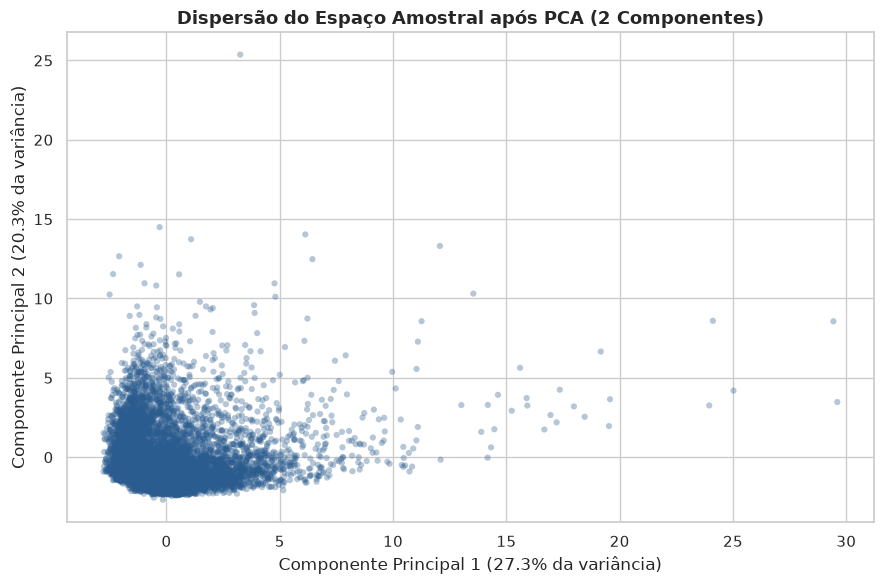

In [7]:
plt.figure(figsize=(9, 6))
plt.scatter(df_pca['PC1'], df_pca['PC2'], alpha=0.35, color='#2b5c8f', edgecolors='none', s=20)
plt.title('Dispersão do Espaço Amostral após PCA (2 Componentes)', fontsize=13, weight='bold')
plt.xlabel(f'Componente Principal 1 ({var_exp[0]*100:.1f}% da variância)')
plt.ylabel(f'Componente Principal 2 ({var_exp[1]*100:.1f}% da variância)')
plt.tight_layout()
plt.show()

## 10. Conclusões e Próximos passos
* **Limpeza e Consistência:** A base passou de 18 atributos para 17 preditores numéricos sem ruídos de identificação nem valores omissos.
* **Escalabilidade:** A normalização z-score garantiu que todos os atributos contribuam com pesos proporcionais nas distâncias euclidianas.
* **Redução Dimensional:** A extração dos componentes principais sintetizou o espaço multidimensional e permitiu inspecionar a densidade e o comportamento dos pontos no plano.
* **Continuidade:** Os dados processados em `df_scaled` e `df_pca` encontram-se prontos para a definição do número ótimo de clusters (Método do Cotovelo e Silhueta) e execução do algoritmo K-Means na entrega final.